In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('labeled_anomalies.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   chan_id            82 non-null     object
 1   spacecraft         82 non-null     object
 2   anomaly_sequences  82 non-null     object
 3   class              82 non-null     object
 4   num_values         82 non-null     int64 
dtypes: int64(1), object(4)
memory usage: 3.3+ KB


In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras import layers, models

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [7]:
from google.colab import files

uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))


KeyboardInterrupt: 

In [8]:
train = np.load("/content/S-1.npy").reshape(-1)
test = np.load("/content/T-1.npy").reshape(-1)

labels_df = pd.read_csv("/content/labeled_anomalies.csv")

print("Training readings:", len(train))
print("Test readings:", len(test))
print("\nLabel columns:", labels_df.columns.tolist())
print("\nFirst few labels:")
display(labels_df.head())


Training readings: 183275
Test readings: 215300

Label columns: ['chan_id', 'spacecraft', 'anomaly_sequences', 'class', 'num_values']

First few labels:


,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


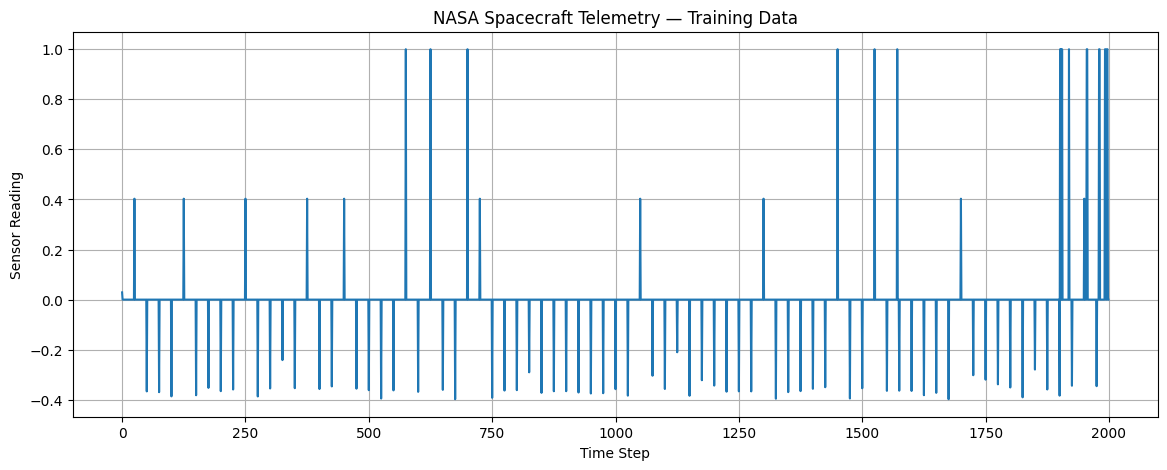

In [9]:
# Display the first 2,000 training readings

plt.figure(figsize=(14, 5))
plt.plot(train[:2000])

plt.title("NASA Spacecraft Telemetry — Training Data")
plt.xlabel("Time Step")
plt.ylabel("Sensor Reading")
plt.grid(True)

plt.show()


In [10]:
print("Available label columns:")
print(labels_df.columns.tolist())
display(labels_df.head(10))

Available label columns:
['chan_id', 'spacecraft', 'anomaly_sequences', 'class', 'num_values']


,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307
5,E-4,SMAP,"[[5450, 8261]]",[point],8354
6,E-5,SMAP,"[[5600, 5920]]",[point],8294
7,E-6,SMAP,"[[5610, 5675]]",[point],8300
8,E-7,SMAP,"[[5394, 5674]]",[point],8310
9,E-8,SMAP,"[[5400, 6022]]",[point],8532


In [11]:
import ast
# Find the label row for channel S-1
CHANNEL_ID = "S-1"

row = labels_df[
    labels_df["chan_id"] == CHANNEL_ID
]

if row.empty:
    raise ValueError("Channel S-1 was not found!")

# Convert the anomaly intervals from text to Python lists
sequences = ast.literal_eval(
    row.iloc[0]["anomaly_sequences"]
)

# Create labels for the test data
y_true = np.zeros(len(test), dtype=int)

for start, end in sequences:
    y_true[max(0, start):min(len(test), end + 1)] = 1

print("Channel:", CHANNEL_ID)
print("Test readings:", len(test))
print("Labeled anomalous readings:", int(y_true.sum()))
print("Normal readings:", int((y_true == 0).sum()))


Channel: S-1
Test readings: 215300
Labeled anomalous readings: 448
Normal readings: 214852


In [12]:
# Check the lengths of the channel files
print("S-1 length:", len(np.load("/content/S-1.npy").reshape(-1)))
print("T-1 length:", len(np.load("/content/T-1.npy").reshape(-1)))

# Check the channel's label metadata
print(
    labels_df.loc[
        labels_df["chan_id"] == "S-1",
        ["chan_id", "spacecraft", "num_values", "anomaly_sequences"]
    ].to_string(index=False)
)


S-1 length: 183275
T-1 length: 215300
chan_id spacecraft  num_values anomaly_sequences
    S-1       SMAP        7331    [[5300, 5747]]


In [28]:

print("Available channel files:\n")

for filename in sorted(os.listdir("/content")):
    if filename.endswith(".npy"):
        arr = np.load(
            os.path.join("/content", filename),
            mmap_mode="r"
        )
        print(f"{filename:12} shape={arr.shape}")

print("\nLabel metadata:")
print(
    labels_df[
        ["chan_id", "spacecraft", "num_values", "anomaly_sequences"]
    ].head(20).to_string(index=False)
)


Available channel files:

A-1.npy      shape=(8640, 25)
A-2.npy      shape=(7914, 25)
A-3.npy      shape=(8205, 25)
A-4.npy      shape=(8080, 25)
A-5.npy      shape=(4693, 25)
A-6.npy      shape=(4453, 25)
A-7.npy      shape=(8631, 25)
A-8.npy      shape=(8375, 25)
A-9.npy      shape=(8434, 25)
B-1.npy      shape=(8044, 25)
C-1.npy      shape=(2264, 55)
C-2.npy      shape=(2051, 55)
D-1.npy      shape=(8509, 25)
D-11.npy     shape=(7431, 25)
D-12.npy     shape=(7918, 25)
D-13.npy     shape=(7663, 25)
D-14.npy     shape=(2625, 55)
D-15.npy     shape=(2158, 55)
D-16.npy     shape=(2191, 55)
D-2.npy      shape=(8595, 25)
D-3.npy      shape=(8640, 25)
D-4.npy      shape=(8473, 25)
D-5.npy      shape=(7628, 25)
D-6.npy      shape=(7884, 25)
D-7.npy      shape=(7642, 25)
D-8.npy      shape=(7874, 25)
D-9.npy      shape=(7406, 25)
E-1.npy      shape=(8516, 25)
E-10.npy     shape=(8505, 25)
E-11.npy     shape=(8514, 25)
E-12.npy     shape=(8512, 25)
E-13.npy     shape=(8640, 25)
E-2.npy      s

In [14]:
# Load the matching S-1 channel
train_array = np.load("/content/S-1.npy")
test_array = np.load("/content/S-1.npy")

print("Training array shape:", train_array.shape)
print("Test array shape:", test_array.shape)


Training array shape: (7331, 25)
Test array shape: (7331, 25)


In [16]:
print("S-1 first 5 rows:")
print(np.load("/content/S-1.npy")[:5])

print("\nS-1 first row shape:")
print(np.load("/content/S-1.npy")[0].shape)

S-1 first 5 rows:
[[ 0.02889305  0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.        ]
 [ 0.40304001  0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.        ]
 [-0.36658466  0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.        ]
 [-0.36971034  0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.        

Signal length: 7331
Minimum: -1.0
Maximum: 0.9999999999999998
Mean: -0.15678924724599463


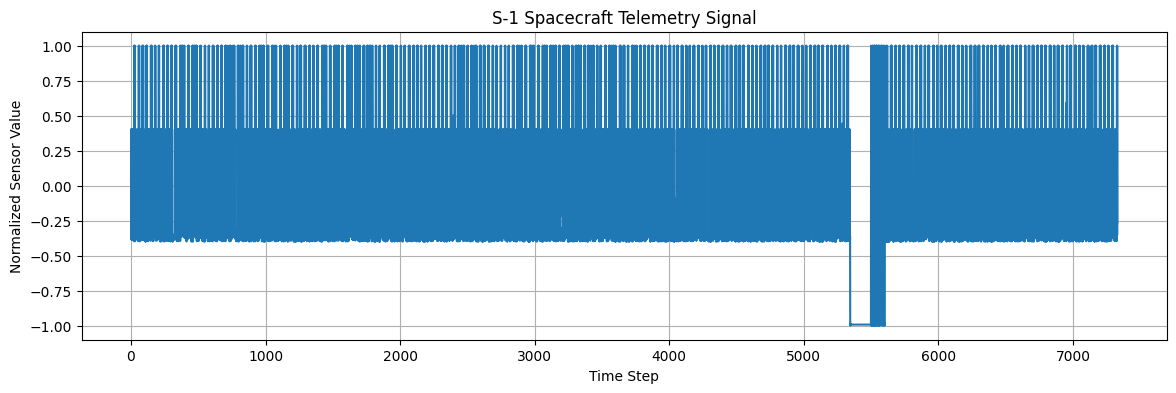

In [17]:
# Select the first feature from each time step
signal = np.load("/content/S-1.npy")[:, 0]

print("Signal length:", len(signal))
print("Minimum:", signal.min())
print("Maximum:", signal.max())
print("Mean:", signal.mean())

plt.figure(figsize=(14, 4))
plt.plot(signal)
plt.title("S-1 Spacecraft Telemetry Signal")
plt.xlabel("Time Step")
plt.ylabel("Normalized Sensor Value")
plt.grid(True)
plt.show()


In [18]:
S1 = np.load("/content/S-1.npy")

print("Nonzero values per feature:")
print(np.count_nonzero(S1, axis=0))

print("\nStandard deviation per feature:")
print(np.std(S1, axis=0))


Nonzero values per feature:
[7331  178   22  153    1  865  653    5    2    3    0    4    1    3
    3    0    0  153  149   77    0  197  181    0    0]

Standard deviation per feature:
[0.46135823 0.15391853 0.05469871 0.14295002 0.01167855 0.32259875
 0.28485023 0.0261069  0.01651483 0.02022507 0.         0.02335231
 0.01167855 0.02022507 0.02022507 0.         0.         0.14295002
 0.14110832 0.10194617 0.         0.16170984 0.15517762 0.
 0.        ]


# **Isolation Forest**

## Using the first feature and a few rolling statistics to build a simple baseline model.

In [19]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Use the first feature as the telemetry signal
signal = np.load("/content/S-1.npy")[:, 0]

# Create simple features from recent sensor behavior
series = pd.Series(signal)

features = pd.DataFrame({
    "value": series,
    "difference": series.diff().fillna(0),
    "rolling_mean": series.rolling(
        20, min_periods=1
    ).mean(),
    "rolling_std": series.rolling(
        20, min_periods=1
    ).std().fillna(0)
})

# Normalize the features
scaler = StandardScaler()
X = scaler.fit_transform(features)

# Fit a baseline anomaly detector
model_if = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

model_if.fit(X)

# -1 means anomaly; 1 means normal
pred_if = (model_if.predict(X) == -1).astype(int)

print("Total readings:", len(signal))
print("Anomalies flagged:", int(pred_if.sum()))


Total readings: 7331
Anomalies flagged: 83


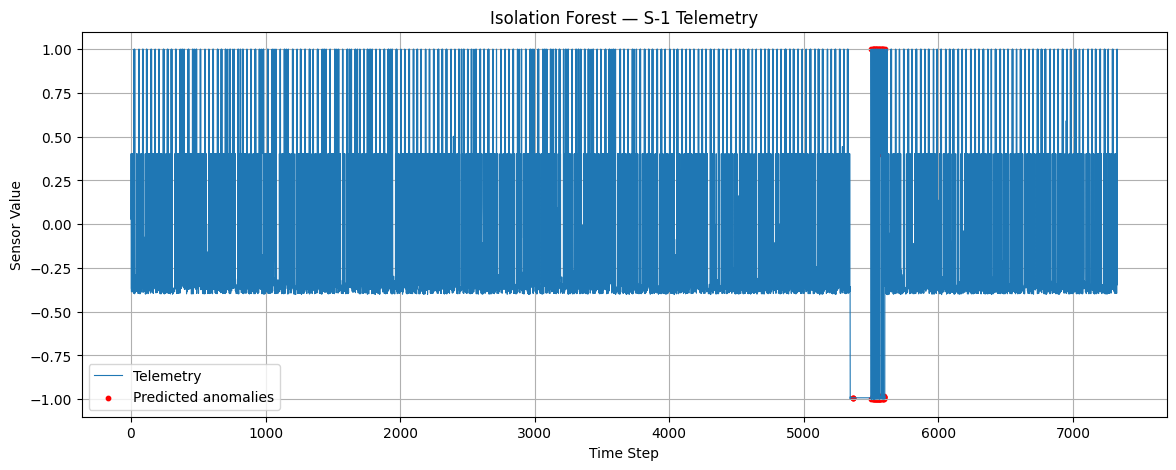

In [20]:
anomaly_indices = np.where(pred_if == 1)[0]

plt.figure(figsize=(14, 5))
plt.plot(signal, label="Telemetry", linewidth=0.8)

plt.scatter(
    anomaly_indices,
    signal[anomaly_indices],
    color="red",
    s=10,
    label="Predicted anomalies"
)

plt.title("Isolation Forest — S-1 Telemetry")
plt.xlabel("Time Step")
plt.ylabel("Sensor Value")
plt.legend()
plt.grid(True)
plt.show()


## Evaluating the model against the labels


In [21]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Ground-truth labels from the S-1 metadata
y_true = np.zeros(len(signal), dtype=int)

row = labels_df[labels_df["chan_id"] == "S-1"]
sequences = ast.literal_eval(row.iloc[0]["anomaly_sequences"])

for start, end in sequences:
    y_true[start:end + 1] = 1

print("True anomaly readings:", int(y_true.sum()))
print("Predicted anomaly readings:", int(pred_if.sum()))

print("\nPrecision:", round(
    precision_score(y_true, pred_if, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_true, pred_if, zero_division=0), 4
))
print("F1 score:", round(
    f1_score(y_true, pred_if, zero_division=0), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, pred_if))


True anomaly readings: 448
Predicted anomaly readings: 83

Precision: 1.0
Recall: 0.1853
F1 score: 0.3126

Confusion matrix:
[[6883    0]
 [ 365   83]]


# **Second model: a dense autoencoder**

In [22]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# X contains the four normalized features from earlier
input_dim = X.shape[1]

autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

history = autoencoder.fit(
    X,
    X,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 1.1796 - val_loss: 0.6465
Epoch 2/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.0736 - val_loss: 0.6038
Epoch 3/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.0003 - val_loss: 0.5613
Epoch 4/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9290 - val_loss: 0.5250
Epoch 5/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8677 - val_loss: 0.4925
Epoch 6/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.8143 - val_loss: 0.4606
Epoch 7/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7701 - val_loss: 0.4266
Epoch 8/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7262 - val_loss: 0.3936
Epoch 9/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6838 - val_loss: 0.3607
Epoch 10/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6410 - val_loss: 0.3242
Epoch 11/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5961 - val_loss: 0.2855
Epoch 12/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5515 - val_

In [23]:

# Reconstruct the input features
reconstructed = autoencoder.predict(X, verbose=0)

# Calculate the reconstruction error for each time step
errors = np.mean((X - reconstructed) ** 2, axis=1)

# Use the 95th percentile as a simple exploratory threshold
threshold = np.percentile(errors, 95)

pred_ae = (errors > threshold).astype(int)

print("Reconstruction threshold:", threshold)
print("Autoencoder anomaly flags:", int(pred_ae.sum()))


Reconstruction threshold: 0.8397093264793942
Autoencoder anomaly flags: 367


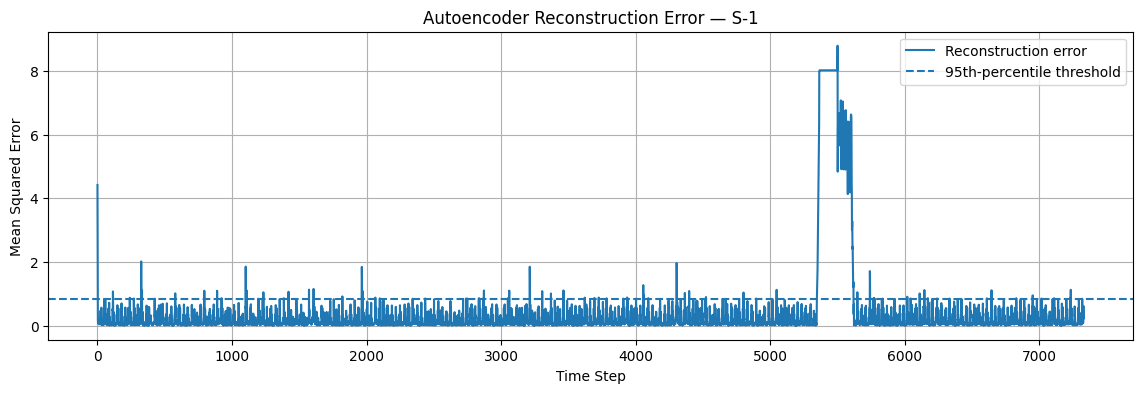

In [24]:

plt.figure(figsize=(14, 4))

plt.plot(errors, label="Reconstruction error")
plt.axhline(
    threshold,
    linestyle="--",
    label="95th-percentile threshold"
)

plt.title("Autoencoder Reconstruction Error — S-1")
plt.xlabel("Time Step")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()


In [26]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_model(name, y_true, predictions):
    print(f"\n{name}")
    print("-" * 35)

    print("Precision:", round(
        precision_score(y_true, predictions, zero_division=0), 4
    ))

    print("Recall:", round(
        recall_score(y_true, predictions, zero_division=0), 4
    ))

    print("F1 score:", round(
        f1_score(y_true, predictions, zero_division=0), 4
    ))

    print("\nConfusion matrix:")
    print(confusion_matrix(y_true, predictions))


evaluate_model("Dense Autoencoder", y_true, pred_ae)



Dense Autoencoder
-----------------------------------
Precision: 0.7493
Recall: 0.6138
F1 score: 0.6748

Confusion matrix:
[[6791   92]
 [ 173  275]]


,Model,Precision,Recall,F1 Score
0,Isolation Forest,1.0000,0.1853,0.3126
1,Dense Autoencoder,0.7493,0.6138,0.6748


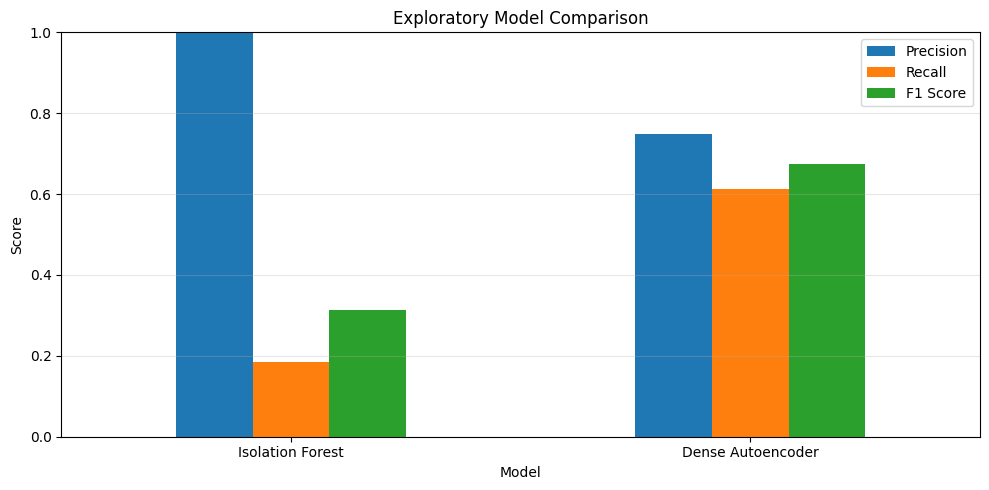

In [27]:
results = pd.DataFrame({
    "Model": ["Isolation Forest", "Dense Autoencoder"],
    "Precision": [1.0000, 0.7493],
    "Recall": [0.1853, 0.6138],
    "F1 Score": [0.3126, 0.6748]
})

display(results.round(4))

results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Exploratory Model Comparison")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
